# SEMMA | Predicting NBA home wins from recent form

Predict the home team's win probability using data available before a regular season game.

[Dataset on Kaggle](https://www.kaggle.com/datasets/nathanlauga/nba-games)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [SAS SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm). Kaggle snapshot version: 10.

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'nathanlauga/nba-games'
KAGGLE_VERSION = 10
EXPECTED_SHA256 = {'games.csv': 'f3e5a0d6f2cb14d6e45aad85de7d346f90d53407e64d573a975bb0de478aa14a', 'teams.csv': '9b933f7245d6b529e6ea0046444e168fd5c3b59986597f61df7cc1ad63f1c8e9'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'games.csv': (26651, 21), 'teams.csv': (30, 14)}
Kaggle snapshot: 10


## 1. Sample

Select completed regular season games. The NBA game ID uses 002 as its regular season prefix when padded to ten digits. Use seasons before 2017–18 for training, 2017–18 for validation, and 2018–19 for assessment. A time-based split simulates predicting future games. We retain earlier regular season games to build team history.

In [2]:
games = tables["games.csv"]
team_names = tables["teams.csv"].set_index("TEAM_ID")["NICKNAME"]
source_columns = ["GAME_DATE_EST", "GAME_ID", "HOME_TEAM_ID", "VISITOR_TEAM_ID", "PTS_home", "PTS_away", "HOME_TEAM_WINS"]
display(games[source_columns].head(5))
regular_season = games.GAME_ID.astype("int64").astype(str).str.zfill(10).str.startswith("002")
games = games.loc[regular_season & games.GAME_STATUS_TEXT.eq("Final")].dropna(subset=source_columns).copy()
games = games.drop_duplicates("GAME_ID")
games["date"] = pd.to_datetime(games.GAME_DATE_EST)
games = games.loc[games.SEASON.le(2018)].sort_values("date")
print("Selected regular season games:", len(games))

,GAME_DATE_EST,GAME_ID,HOME_TEAM_ID,VISITOR_TEAM_ID,PTS_home,PTS_away,HOME_TEAM_WINS
0,2022-12-22,22200477,1610612740,1610612759,126.0,117.0,1
1,2022-12-22,22200478,1610612762,1610612764,120.0,112.0,1
2,2022-12-21,22200466,1610612739,1610612749,114.0,106.0,1
3,2022-12-21,22200467,1610612755,1610612765,113.0,93.0,1
4,2022-12-21,22200468,1610612737,1610612741,108.0,110.0,0


Selected regular season games: 19398


The historical outcome must agree with the score. Count the completed games by season before requiring team history.

In [3]:
assert games.PTS_home.ne(games.PTS_away).all()
assert games.HOME_TEAM_WINS.eq(games.PTS_home.gt(games.PTS_away)).all()
display(games.groupby("SEASON").size().rename("games_before_history_requirement").to_frame())

,games_before_history_requirement
SEASON,
2003,1189
2004,1230
2005,1230
2006,1230
2007,1230
2008,1230
2009,1230
2010,1230
2011,990


## 2. Explore

Inspect the share of home wins by season using training years. The scores are postgame fields. They label the current outcome and help calculate past form for later games.

,size,mean
SEASON,,
2012,1229,0.611880
2013,1230,0.580488
2014,1230,0.574797
2015,1230,0.588618
2016,1230,0.583740


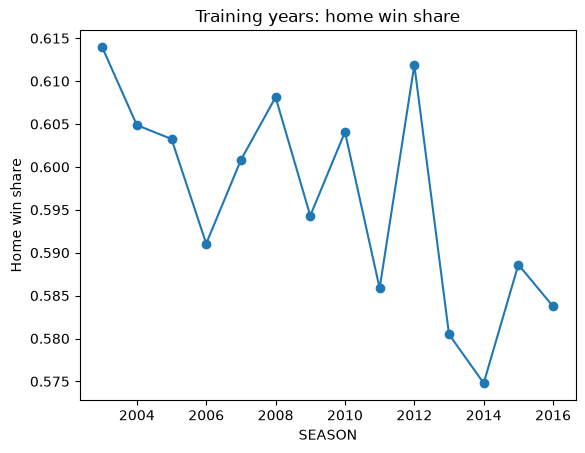

In [4]:
home_share = games.loc[games.SEASON.lt(2017)].groupby("SEASON").HOME_TEAM_WINS.agg(["size", "mean"])
display(home_share.tail())
home_share["mean"].plot(marker="o", title="Training years: home win share", ylabel="Home win share")
plt.show()

## 3. Modify

A rolling statistic summarizes the most recent records. For each team, calculate the average of its five most recent wins and point margins. Shift the values by one game so the current score cannot influence its own prediction. Require five earlier games for both teams. Compute days of rest between dates.

In [5]:
common = ["GAME_ID", "date"]
home = games[common + ["HOME_TEAM_ID", "PTS_home", "PTS_away"]].rename(columns={"HOME_TEAM_ID": "team", "PTS_home": "points", "PTS_away": "opponent_points"})
away = games[common + ["VISITOR_TEAM_ID", "PTS_home", "PTS_away"]].rename(columns={"VISITOR_TEAM_ID": "team", "PTS_away": "points", "PTS_home": "opponent_points"})
team_games = pd.concat([home, away], ignore_index=True).sort_values(["team", "date", "GAME_ID"])
assert not team_games.duplicated(["team", "date"]).any()
team_games["margin"] = team_games.points - team_games.opponent_points
team_games["win"] = team_games.margin.gt(0).astype(int)
by_team = team_games.groupby("team")
team_games["recent_win_rate"] = by_team.win.transform(lambda values: values.shift().rolling(5).mean())
team_games["recent_margin"] = by_team.margin.transform(lambda values: values.shift().rolling(5).mean())
team_games["rest_days"] = by_team.date.diff().dt.days.sub(1).clip(0, 7)

In [6]:
team_features = ["recent_win_rate", "recent_margin", "rest_days"]
model_rows = games[["GAME_ID", "HOME_TEAM_ID", "VISITOR_TEAM_ID", "date", "SEASON", "HOME_TEAM_WINS"]].copy()
for side, team_key in [("home", "HOME_TEAM_ID"), ("away", "VISITOR_TEAM_ID")]:
    lookup = team_games[["GAME_ID", "team", *team_features]].rename(columns={"team": team_key, **{name: f"{side}_{name}" for name in team_features}})
    model_rows = model_rows.merge(lookup, on=["GAME_ID", team_key], validate="one_to_one")

FEATURES = [f"{name}_difference" for name in team_features]
for name, column in zip(team_features, FEATURES):
    model_rows[column] = model_rows[f"home_{name}"] - model_rows[f"away_{name}"]
model_rows = model_rows.dropna(subset=FEATURES)
train = model_rows.loc[model_rows.SEASON.lt(2017)]
validation = model_rows.loc[model_rows.SEASON.eq(2017)]
test = model_rows.loc[model_rows.SEASON.eq(2018)]
assert train.date.max() < validation.date.min() < validation.date.max() < test.date.min()
display(model_rows[["date", *FEATURES, "HOME_TEAM_WINS"]].head())

,date,recent_win_rate_difference,recent_margin_difference,rest_days_difference,HOME_TEAM_WINS
70,2003-11-07,0.0,-13.8,0.0,0
72,2003-11-07,-0.2,-3.0,0.0,0
73,2003-11-07,-0.2,-6.6,1.0,1
76,2003-11-08,0.2,-1.6,0.0,1
77,2003-11-08,0.4,19.2,0.0,0


In [7]:
example_game = test.sort_values(["date", "GAME_ID"]).iloc[0]
example_history = team_games.loc[
    team_games.team.eq(example_game.HOME_TEAM_ID) & team_games.date.lt(example_game.date)
].tail(5)
display(example_history[["date", "win", "margin"]])
assert np.isclose(example_history.win.mean(), example_game.home_recent_win_rate)
assert np.isclose(example_history.margin.mean(), example_game.home_recent_margin)
print("Manual trace: the five rows reproduce the two home form features.")

,date,win,margin
37506,2018-04-04,0,-18.0
18118,2018-04-06,1,7.0
18138,2018-04-08,0,-6.0
37550,2018-04-10,0,-12.0
18167,2018-04-11,1,13.0


Manual trace: the five rows reproduce the two home form features.


This window can cross an offseason. Rest counts are capped at seven days. A roster change can make prior-season form less representative of a season opener.

An opening game can depend on games from the previous season. Report how many rows satisfy the history requirement and show the home win rate of the final training cohort.

In [8]:
selected_by_season = games.groupby("SEASON").size()
eligible_by_season = model_rows.groupby("SEASON").size()
display(pd.concat([selected_by_season.rename("selected"), eligible_by_season.rename("eligible")], axis=1))
print("Eligible training home win rate:", round(train.HOME_TEAM_WINS.mean(), 4))

,selected,eligible
SEASON,,
2003,1189,1111
2004,1230,1225
2005,1230,1230
2006,1230,1230
2007,1230,1230
2008,1230,1230
2009,1230,1230
2010,1230,1230
2011,990,990


Eligible training home win rate: 0.5962


## 4. Model

Logistic regression estimates win probability from a weighted combination of the three features. A random forest averages predictions from multiple decision trees. The dummy baseline uses the training home-win rate for every game. Rank the two learned models using validation log loss, which penalizes confident wrong probabilities.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

target = "HOME_TEAM_WINS"
models = {
    "Home win rate": DummyClassifier(strategy="prior"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=35, random_state=255, n_jobs=2),
}
validation_loss = {}
for label, estimator in models.items():
    estimator.fit(train[FEATURES], train[target])
    validation_loss[label] = log_loss(validation[target], estimator.predict_proba(validation[FEATURES]))
display(pd.Series(validation_loss, name="validation_log_loss").sort_values().round(4))
selected = min(("Logistic regression", "Random forest"), key=validation_loss.get)
print("Selected from validation:", selected)

Logistic regression    0.6446
Random forest          0.6494
Home win rate          0.6813
Name: validation_log_loss, dtype: float64

Selected from validation: Logistic regression


## 5. Assess

Refit on training and validation data, then measure performance on 2018–19. Accuracy is the share of correct labels. ROC AUC measures how well the model ranks home wins above losses. Include a single historical game to show what the prediction looks like.

In [10]:
development = pd.concat([train, validation])
scores = {}
for label, estimator in models.items():
    estimator.fit(development[FEATURES], development[target])
    probability = estimator.predict_proba(test[FEATURES])[:, 1]
    scores[label] = {
        "accuracy": accuracy_score(test[target], probability >= 0.5),
        "log_loss": log_loss(test[target], probability),
        "roc_auc": roc_auc_score(test[target], probability),
    }
display(pd.DataFrame(scores).T.round(4))

,accuracy,log_loss,roc_auc
Home win rate,0.5927,0.6759,0.5000
Logistic regression,0.6317,0.6373,0.6598
Random forest,0.6268,0.6417,0.6516


In [11]:
example = test.sort_values(["date", "GAME_ID"]).iloc[[0]]
row = example.iloc[0]
example_result = {
    "date": str(row.date.date()),
    "home": team_names.loc[row.HOME_TEAM_ID],
    "away": team_names.loc[row.VISITOR_TEAM_ID],
    "model_home_win_probability": float(models[selected].predict_proba(example[FEATURES])[0, 1]),
    "actual_home_win": bool(row[target]),
}
display(pd.Series(example_result))
save_json("assessment.json", {
    "split_rows": {"train": len(train), "validation": len(validation), "test": len(test)},
    "selected": selected, "validation_log_loss": validation_loss,
    "metrics": scores, "example": example_result,
})

date                          2018-10-16
home                             Celtics
away                               76ers
model_home_win_probability      0.371332
actual_home_win                     True
dtype: object

Check the validation-selected model's calibration on the held-out season. Calibration compares mean predicted probability with the observed share of wins. Read the count before interpreting each group.

In [12]:
assessment_probability = models[selected].predict_proba(test[FEATURES])[:, 1]
calibration = pd.DataFrame({"predicted": assessment_probability, "home_won": test[target].to_numpy()})
bins = pd.cut(calibration.predicted, [0, .4, .5, .6, .7, 1], include_lowest=True)
display(calibration.groupby(bins, observed=True).agg(games=("home_won", "size"), mean_prediction=("predicted", "mean"), observed=("home_won", "mean")).round(4))

,games,mean_prediction,observed
predicted,,,
"(-0.001, 0.4]",125,0.3331,0.4000
"(0.4, 0.5]",217,0.4575,0.4470
"(0.5, 0.6]",273,0.5541,0.5568
"(0.6, 0.7]",318,0.6506,0.6352
"(0.7, 1.0]",297,0.7676,0.7677


The implementation uses Python in Colab and follows the five SEMMA stages. The comparison describes this held-out season. It does not establish that the winning model leads across all seasons.